# Dataset exploration and EDA

This notebook shows how we inspected the local NF-CSE-CIC-IDS2018-V2 flow dataset before training. A flow row summarizes a network connection; it is not packet payload or message content. The notebook reads the dataset from disk in batches so it does not load all 17 million rows into a pandas DataFrame.

The file is intentionally not stored in this repository. Put `NF-CSE-CIC-IDS2018-V2.parquet` in `data/raw/` before running the data cells. Install `pyarrow`, `numpy`, `matplotlib`, and `seaborn` in your Python environment.

The main questions are: what is in the file, how do the labels relate, how uneven are the attack categories, and which data-quality decisions affect later modeling?

In [1]:
from collections import Counter, defaultdict
import json
from pathlib import Path
import pyarrow.parquet as pq


In [2]:
root = Path.cwd()
while not (root / "data/raw/NF-CSE-CIC-IDS2018-V2.parquet").exists() and root != root.parent:
    root = root.parent

data_path = root / "data/raw/NF-CSE-CIC-IDS2018-V2.parquet"
parquet = pq.ParquetFile(data_path)
print(f"Rows: {parquet.metadata.num_rows:,}")
print(f"Columns: {len(parquet.schema_arrow.names)}")
print(parquet.schema_arrow.names)


Rows: 17,129,715
Columns: 43
['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label', 'Attack']


## Count the labels

This reads just the two label columns in batches. It does not load the full data table into memory.


In [3]:
attack_counts = Counter()
label_counts = Counter()
labels_by_attack = defaultdict(Counter)

for batch in parquet.iter_batches(columns=["Label", "Attack"], batch_size=100_000):
    labels = batch.column("Label").to_pylist()
    attacks = batch.column("Attack").to_pylist()
    label_counts.update(labels)
    attack_counts.update(attacks)
    for attack, label in zip(attacks, labels):
        labels_by_attack[attack][label] += 1

print("Binary labels:", dict(label_counts))
print("Attack categories:", len(attack_counts))
for name, count in attack_counts.most_common():
    print(f"{name}: {count:,}")


Binary labels: {1: 2028030, 0: 15101685}
Attack categories: 15
Benign: 15,101,685
DDOS attack-HOIC: 1,066,881
DoS attacks-Hulk: 432,648
DDoS attacks-LOIC-HTTP: 207,078
Infilteration: 115,513
SSH-Bruteforce: 94,979
Bot: 28,033
DoS attacks-GoldenEye: 27,723
FTP-BruteForce: 25,933
DoS attacks-SlowHTTPTest: 14,116
DoS attacks-Slowloris: 9,512
Brute Force -Web: 2,143
DDOS attack-LOIC-UDP: 2,112
Brute Force -XSS: 927
SQL Injection: 432


## Check data quality and ranges

This pass checks nulls, non-finite numeric values, numeric ranges, and constant columns in batches. It also measures the duration-zero pattern by binary label. The results below are dataset observations; they do not by themselves prove that a feature is safe or unsafe for a deployed model.

In [ ]:
import numpy as np
from collections import Counter

columns = parquet.schema_arrow.names
numeric_columns = [name for name in columns if name not in {"Label", "Attack"}]
null_counts = Counter()
nonfinite_counts = Counter()
ranges = {name: [float("inf"), float("-inf")] for name in numeric_columns}
distinct = {name: set() for name in numeric_columns}
duration_zeros = Counter()

for batch in parquet.iter_batches(batch_size=100_000):
    labels = np.asarray(batch.column("Label").to_pylist())
    duration = batch.column("FLOW_DURATION_MILLISECONDS").to_numpy(zero_copy_only=False)
    for label in (0, 1):
        duration_zeros[label] += int(np.sum((labels == label) & (duration == 0)))
    for name in columns:
        null_counts[name] += batch.column(name).null_count
    for name in numeric_columns:
        values = batch.column(name).to_numpy(zero_copy_only=False)
        finite = np.isfinite(values)
        nonfinite_counts[name] += int((~finite).sum())
        values = values[finite]
        if values.size:
            ranges[name][0] = min(ranges[name][0], float(values.min()))
            ranges[name][1] = max(ranges[name][1], float(values.max()))
            if len(distinct[name]) < 3:
                distinct[name].update(np.unique(values).tolist())
                if len(distinct[name]) > 2:
                    distinct[name] = {None, False, True}

print("Columns with nulls:", {k: v for k, v in null_counts.items() if v})
print("Numeric columns with non-finite values:", {k: v for k, v in nonfinite_counts.items() if v})
print("Constant numeric columns:", [k for k, v in distinct.items() if len(v) == 1])
print("Duration-zero counts by Label:", dict(duration_zeros))
print("Extreme directional-rate ranges:")
for name in ("SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"):
    print(name, ranges[name])


The full audit found no nulls or non-finite numeric values, and `FTP_COMMAND_RET_CODE` is constant at zero. The two directional rate fields reach values far outside the range representable by `float32`, so the baseline excluded them until their formulas and units can be checked. Duration is zero for about 95.68% of benign rows and 12.75% of attack rows. That association deserves investigation; it is not proof of label leakage.

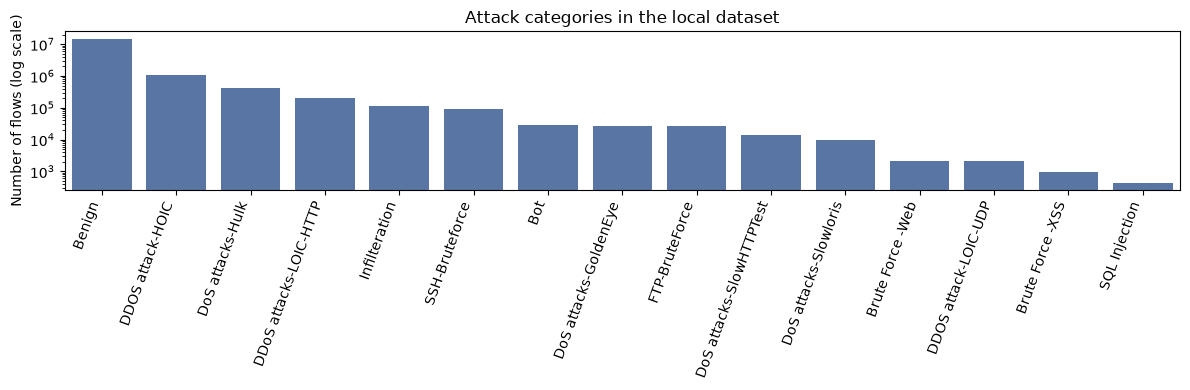

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

names, counts = zip(*attack_counts.most_common())
plt.figure(figsize=(12, 4))
sns.barplot(x=list(names), y=list(counts), color="#4c72b0")
plt.yscale("log")
plt.xticks(rotation=70, ha="right")
plt.ylabel("Number of flows (log scale)")
plt.title("Attack categories in the local dataset")
plt.tight_layout()
plt.show()


`Label` is the binary target: 0 means benign and 1 means attack. `Attack` gives the more specific category. These are known labels from the dataset; live network traffic would not arrive with an answer attached.


In [5]:
inconsistent = {name: dict(counts) for name, counts in labels_by_attack.items() if len(counts) > 1}
print("Categories mapped to more than one binary label:", inconsistent or "none")


Categories mapped to more than one binary label: none


## What the saved experiment found

These scores come from held-out samples with weights that account for the class caps. They are estimates for this dataset, not a guarantee for another network.


In [6]:
bundle = json.loads((root / "web/demo_bundle.json").read_text())

binary = bundle["binary"]
multiclass = bundle["multiclass"]
print(f"Binary attack F1: {binary['attack_f1']:.4f}")
print(f"Binary attack precision: {binary['attack_precision']:.4f}")
print(f"Binary attack recall: {binary['attack_recall']:.4f}")
print(f"Multiclass macro-F1: {multiclass['macro_f1']:.4f}")
print(f"Multiclass accuracy: {multiclass['accuracy']:.4f}")
print(f"SQL Injection test examples: {multiclass['sql_test_support']}")


Binary attack F1: 0.9792
Binary attack precision: 0.9955
Binary attack recall: 0.9635
Multiclass macro-F1: 0.7887
Multiclass accuracy: 0.9942
SQL Injection test examples: 65


In [7]:
for example in bundle["examples"]:
    print(f"{example['title']}: dataset label={example['known_attack']}; "
          f"model guess={example['multiclass']['prediction']}")


Everyday web browsing: dataset label=Benign; model guess=Benign
Traffic surge (DDoS): dataset label=DDOS attack-HOIC; model guess=DDOS attack-HOIC
Suspicious access (Infilteration): dataset label=Infilteration; model guess=Infilteration
Rare SQL Injection example: dataset label=SQL Injection; model guess=DDOS attack-HOIC


## Main takeaway

The dataset has 17,129,715 rows and 43 columns: 41 numeric flow features plus `Label` and `Attack`. `Label` is consistent with `Attack`: Benign maps to 0 and every named attack category maps to 1. The class distribution is highly imbalanced, and the category plot uses a logarithmic vertical axis so rare attacks remain visible.

These checks guided the feature and metric choices in the modeling notebook. They do not establish that train and test records are independent: duplicate flows and capture/session-level dependence need further analysis.